# GND Gender Classifier Training

This notebook trains a gender classifier using the complete GND (Gemeinsame Normdatei) person authority dataset from the German National Library (DNB).

**Data Source:** https://data.dnb.de/GND/authorities-gnd-person_dnbmarc.mrc.xml.gz

**Goal:** Extract person records with name, birth date, and gender information to train a robust gender classification model.

In [4]:
!pip install lxml polars scikit-learn xgboost matplotlib seaborn tqdm requests numpy gender-guesser cupy-cuda12x

## 1. Download and Extract GND Data

Download the complete GND person authority dataset in MARC 21 XML format.

In [5]:
import requests
import gzip
from pathlib import Path
from tqdm import tqdm
import polars as pl

# Setup paths
data_dir = Path('/mnt/data/userfiles/westphal/schleiermacher/gender/gender/data/raw/GND')
data_dir.mkdir(parents=True, exist_ok=True)

# URLs
GND_URL = 'https://data.dnb.de/GND/authorities-gnd-person_dnbmarc.mrc.xml.gz'
gz_file = data_dir / 'authorities-gnd-person_dnbmarc.mrc.xml.gz'
xml_file = data_dir / 'authorities-gnd-person_dnbmarc.mrc.xml'

print(f"Data directory: {data_dir}")
print(f"Download URL: {GND_URL}")

# Check if the gz file already exists
if not gz_file.exists():
    print(f"No GZ file found at {gz_file}. Downloading from {GND_URL}...")
else:
    print(f"GZ file already exists at {gz_file}")

Data directory: /mnt/data/userfiles/westphal/schleiermacher/gender/gender/data/raw/GND
Download URL: https://data.dnb.de/GND/authorities-gnd-person_dnbmarc.mrc.xml.gz
GZ file already exists at /mnt/data/userfiles/westphal/schleiermacher/gender/gender/data/raw/GND/authorities-gnd-person_dnbmarc.mrc.xml.gz


In [6]:
# Download the GND dataset (warning: this is a large file, ~2-3 GB compressed)
if not gz_file.exists():
    print(f"Downloading GND dataset from {GND_URL}...")
    print("This may take several minutes (file is ~2-3 GB)...")

    response = requests.get(GND_URL, stream=True)
    response.raise_for_status()

    # Get total file size
    total_size = int(response.headers.get('content-length', 0))
    block_size = 8192

    # Download with progress bar
    with open(gz_file, 'wb') as f:
        with tqdm(total=total_size, unit='iB', unit_scale=True, desc='Downloading') as pbar:
            for chunk in response.iter_content(chunk_size=block_size):
                if chunk:
                    f.write(chunk)
                    pbar.update(len(chunk))

    print(f"✓ Download complete: {gz_file}")
else:
    print(f"✓ File already downloaded: {gz_file}")

# Check file size
file_size_mb = gz_file.stat().st_size / (1024 * 1024)
print(f"  Compressed file size: {file_size_mb:.2f} MB")

✓ File already downloaded: /mnt/data/userfiles/westphal/schleiermacher/gender/gender/data/raw/GND/authorities-gnd-person_dnbmarc.mrc.xml.gz
  Compressed file size: 1563.51 MB


In [7]:
# Extract the gzipped file
if not xml_file.exists():
    print(f"Extracting {gz_file.name}...")
    print("This may take several minutes...")

    with gzip.open(gz_file, 'rb') as f_in:
        with open(xml_file, 'wb') as f_out:
            # Extract in chunks with progress
            chunk_size = 1024 * 1024  # 1MB chunks
            while True:
                chunk = f_in.read(chunk_size)
                if not chunk:
                    break
                f_out.write(chunk)

    print(f"✓ Extraction complete: {xml_file}")
else:
    print(f"✓ File already extracted: {xml_file}")

# Check extracted file size
xml_size_gb = xml_file.stat().st_size / (1024 * 1024 * 1024)
print(f"  Extracted file size: {xml_size_gb:.2f} GB")

✓ File already extracted: /mnt/data/userfiles/westphal/schleiermacher/gender/gender/data/raw/GND/authorities-gnd-person_dnbmarc.mrc.xml
  Extracted file size: 24.71 GB


## 2. Parse MARC 21 XML Records

Parse the MARC 21 XML file to extract individual person records. The file uses the MARC21 namespace.

In [8]:
# MARC21 XML namespace
MARC_NS = {'marc': 'http://www.loc.gov/MARC21/slim'}

# Test parse - read first few records to understand structure
print("Testing XML structure with first few records...")
context = etree.iterparse(str(xml_file), events=('end',), tag='{http://www.loc.gov/MARC21/slim}record')
record_count = 0

for event, elem in context:
    record_count += 1

    if record_count <= 3:  # Show first 3 records
        print(f"\n{'='*60}")
        print(f"Record {record_count}:")
        print(f"{'='*60}")

        # Show all datafields
        for datafield in elem.xpath('.//marc:datafield', namespaces=MARC_NS):
            tag = datafield.get('tag')
            ind1 = datafield.get('ind1', ' ')
            ind2 = datafield.get('ind2', ' ')

            subfields = []
            for subfield in datafield.xpath('marc:subfield', namespaces=MARC_NS):
                code = subfield.get('code')
                value = subfield.text
                subfields.append(f"${code}: {value}")

            if subfields:
                print(f"  {tag} (ind1='{ind1}', ind2='{ind2}'): {', '.join(subfields)}")

    # Clear element to save memory
    elem.clear()
    while elem.getprevious() is not None:
        del elem.getparent()[0]

    if record_count >= 10:  # Stop after checking structure
        break

del context
print(f"\n✓ XML structure test complete. Total records checked: {record_count}")

Testing XML structure with first few records...

Record 1:
  024 (ind1='7', ind2=' '): $a: 16126667-8, $0: http://d-nb.info/gnd/16126667-8, $2: gnd
  035 (ind1=' ', ind2=' '): $a: (DE-101)051224666
  035 (ind1=' ', ind2=' '): $a: (DE-588)16126667-8
  035 (ind1=' ', ind2=' '): $z: (DE-588b)16126667-8, $9: v:zg
  040 (ind1=' ', ind2=' '): $a: DE-12, $c: DE-12, $9: r:DE-12, $b: ger, $d: 1841
  042 (ind1=' ', ind2=' '): $a: gnd6
  043 (ind1=' ', ind2=' '): $c: ZZ
  075 (ind1=' ', ind2=' '): $b: p, $2: gndgen
  075 (ind1=' ', ind2=' '): $b: piz, $2: gndspec
  079 (ind1=' ', ind2=' '): $a: g, $q: f
  100 (ind1='0', ind2=' '): $a: Paulus, $g: a Sancto Bartholomaeo
  377 (ind1=' ', ind2='7'): $a: lat, $2: iso639-2b
  913 (ind1=' ', ind2=' '): $S: gkd, $i: a, $a: Paulus <a Sancto Bartholomaeo>, $0: (DE-588b)16126667-8

Record 2:
  024 (ind1='7', ind2=' '): $a: 100000193, $0: http://d-nb.info/gnd/100000193, $2: gnd
  035 (ind1=' ', ind2=' '): $a: (DE-101)100000193
  035 (ind1=' ', ind2=' '): $a:

## 3. Extract Relevant Fields

Extract the key MARC21 fields we need:
- **100$a**: Personal name (main entry)
- **375$a**: Gender
- **548$a**: Date of birth and death (with relation type indicators)
- **400$a**: Alternative name forms (if available)

In [9]:
def extract_person_data(record):
    """Extract relevant person data from a MARC21 record."""
    person_data = {
        'name': None,
        'forename': None,
        'surname': None,
        'birth_date': None,
        'death_date': None,
        'gender': None,
        'alt_names': []
    }

    # Extract fields using XPath
    for datafield in record.xpath('.//marc:datafield', namespaces=MARC_NS):
        tag = datafield.get('tag')

        # 100 = Personal name (main entry)
        if tag == '100':
            for subfield in datafield.xpath('marc:subfield', namespaces=MARC_NS):
                code = subfield.get('code')
                if code == 'a':  # Personal name
                    full_name = subfield.text
                    person_data['name'] = full_name

                    # Try to split into surname, forename
                    if ',' in full_name:
                        parts = full_name.split(',', 1)
                        person_data['surname'] = parts[0].strip()
                        person_data['forename'] = parts[1].strip() if len(parts) > 1 else None
                elif code == 'd' and subfield.text:
                    # 100 $d contains birth/death dates, e.g. "1776-1854" or "1776-"
                    date_str = subfield.text.strip().rstrip('.')
                    if '-' in date_str:
                        parts = date_str.split('-', 1)
                        birth = parts[0].strip()
                        death = parts[1].strip() if len(parts) > 1 else None
                        if birth:
                            person_data['birth_date'] = birth
                        if death:
                            person_data['death_date'] = death
                    elif date_str:
                        person_data['birth_date'] = date_str

        # 375 = Gender
        elif tag == '375':
            for subfield in datafield.xpath('marc:subfield', namespaces=MARC_NS):
                code = subfield.get('code')
                if code == 'a':  # Gender
                    gender_value = subfield.text
                    if gender_value:
                        # Normalize gender values
                        gender_lower = gender_value.lower()
                        if 'männlich' in gender_lower or 'male' in gender_lower:
                            person_data['gender'] = 'male'
                        elif 'weiblich' in gender_lower or 'female' in gender_lower:
                            person_data['gender'] = 'female'
                        else:
                            person_data['gender'] = gender_value

        # 548 = Chronological term / dates (birth/death)
        # GND uses $4 (relationship code) or $i (text indicator)
        elif tag == '548':
            is_birth_date = False
            is_death_date = False
            date_value = None

            for subfield in datafield.xpath('marc:subfield', namespaces=MARC_NS):
                code = subfield.get('code')
                if code == 'a':  # Date value
                    date_value = subfield.text
                elif code == 'i' and subfield.text:
                    # Text relationship indicator
                    text_lower = subfield.text.lower()
                    if 'geburt' in text_lower or 'birth' in text_lower:
                        is_birth_date = True
                    elif 'tod' in text_lower or 'death' in text_lower or 'gestorben' in text_lower:
                        is_death_date = True
                elif code == '4' and subfield.text:
                    # GND relationship codes: datb=birth, datd=death, datl=lifespan
                    rel_code = subfield.text.strip().lower()
                    if rel_code == 'datb':
                        is_birth_date = True
                    elif rel_code == 'datd':
                        is_death_date = True
                    elif rel_code == 'datl' and date_value:
                        # Lifespan "YYYY-YYYY" — parse both
                        if '-' in date_value:
                            parts = date_value.split('-', 1)
                            if parts[0].strip():
                                person_data['birth_date'] = parts[0].strip()
                            if parts[1].strip():
                                person_data['death_date'] = parts[1].strip()

            # Apply birth/death assignment after scanning all subfields
            if date_value:
                if is_birth_date and not person_data['birth_date']:
                    person_data['birth_date'] = date_value
                elif is_death_date and not person_data['death_date']:
                    person_data['death_date'] = date_value

        # 400 = Alternative name forms
        elif tag == '400':
            for subfield in datafield.xpath('marc:subfield', namespaces=MARC_NS):
                code = subfield.get('code')
                if code == 'a':
                    alt_name = subfield.text
                    if alt_name and alt_name not in person_data['alt_names']:
                        person_data['alt_names'].append(alt_name)

    return person_data

print("✓ Extraction function defined")


✓ Extraction function defined


## 4. Process All Records and Filter

Process all records in the dataset and filter for complete entries with gender information.

In [10]:
# Process all records (this will take a while - millions of records)
print("Processing GND records...")
print("This may take 10-30 minutes depending on your system...")

all_persons = []
records_processed = 0
records_with_gender = 0
records_with_name = 0

# Use iterparse for memory-efficient processing
context = etree.iterparse(str(xml_file), events=('end',), tag='{http://www.loc.gov/MARC21/slim}record')

for event, elem in context:
    records_processed += 1

    # Extract person data
    person_data = extract_person_data(elem)

    # Count records with key fields
    if person_data['name']:
        records_with_name += 1
    if person_data['gender']:
        records_with_gender += 1

    # Only keep records with both name AND gender
    if person_data['name'] and person_data['gender']:
        all_persons.append(person_data)

    # Clear element to save memory (important for lxml)
    elem.clear()
    while elem.getprevious() is not None:
        del elem.getparent()[0]

    # Progress update every 100k records
    if records_processed % 100000 == 0:
        print(f"  Processed {records_processed:,} records | "
              f"With gender: {records_with_gender:,} | "
              f"Complete entries: {len(all_persons):,}")

# Clean up
del context

print(f"\n{'='*60}")
print(f"Processing complete!")
print(f"{'='*60}")
print(f"Total records processed: {records_processed:,}")
print(f"Records with name: {records_with_name:,}")
print(f"Records with gender: {records_with_gender:,}")
print(f"Complete records (name + gender): {len(all_persons):,}")
print(f"{'='*60}")

Processing GND records...
This may take 10-30 minutes depending on your system...
  Processed 100,000 records | With gender: 41,493 | Complete entries: 41,493
  Processed 200,000 records | With gender: 111,945 | Complete entries: 111,945
  Processed 300,000 records | With gender: 205,187 | Complete entries: 205,187
  Processed 400,000 records | With gender: 258,867 | Complete entries: 258,867
  Processed 500,000 records | With gender: 284,352 | Complete entries: 284,352
  Processed 600,000 records | With gender: 310,052 | Complete entries: 310,052
  Processed 700,000 records | With gender: 337,357 | Complete entries: 337,357
  Processed 800,000 records | With gender: 361,841 | Complete entries: 361,841
  Processed 900,000 records | With gender: 373,136 | Complete entries: 373,136
  Processed 1,000,000 records | With gender: 383,022 | Complete entries: 383,022
  Processed 1,100,000 records | With gender: 412,514 | Complete entries: 412,514
  Processed 1,200,000 records | With gender: 44

## 5. Convert to DataFrame and Explore Data

Convert the extracted data to a pandas DataFrame for easier analysis.

In [11]:

# Convert to Polars DataFrame
df_gnd = pl.DataFrame(all_persons)

# Convert alt_names list to string for easier handling, drop raw list column
df_gnd = df_gnd.with_columns([
    pl.col('alt_names').list.join('; ').alias('alt_names_str'),
    pl.col('alt_names').list.len().alias('alt_names_count')
]).drop('alt_names')

print(f"DataFrame created with {len(df_gnd):,} records")
print(f"\nDataFrame shape: {df_gnd.shape}")
print(f"\nColumn data types:")
print(df_gnd.dtypes)
print(f"\nFirst few records:")
df_gnd.head(10)


DataFrame created with 3,254,656 records

DataFrame shape: (3254656, 8)

Column data types:
[String, String, String, String, String, String, String, UInt32]

First few records:


name,forename,surname,birth_date,death_date,gender,alt_names_str,alt_names_count
str,str,str,str,str,str,str,u32
"""Bauer, Johann Gottfried""","""Johann Gottfried""","""Bauer""","""1695""","""1763""","""1""","""Bauer, Johannes Gottfried; Bau…",18
"""Baur, Johann Wilhelm""","""Johann Wilhelm""","""Baur""","""1607""","""1642""","""1""","""Baur, W.; Baur, Johannes Guili…",11
"""Mosca, Giuseppe""","""Giuseppe""","""Mosca""","""1772""","""1839""","""1""","""Mosca, Gioseppe""",1
"""Ampzing, Samuel""","""Samuel""","""Ampzing""","""1590""","""1632""","""1""","""Ampsinck, Samuel; Ampsingius, …",4
"""Vacchiery, Karl Albrecht von""","""Karl Albrecht von""","""Vacchiery""","""1746""","""1807""","""1""","""Vacchiery, Carl Albrecht von…",12
"""Chlingensperg, Christoph von""","""Christoph von""","""Chlingensperg""","""1651""","""1720""","""1""","""Chlingensberg, Christoph von…",12
"""Baïf, Lazare de""","""Lazare de""","""Baïf""","""1496""","""1547""","""1""","""Baïf, Lazare; Baïf, Lasare; …",8
"""Ancher, Peder Kofod""","""Peder Kofod""","""Ancher""","""1710""","""1788""","""1""","""Ancher, Petrus Kofod; Ancher, …",10
"""Plotho, Erich Christoph von""","""Erich Christoph von""","""Plotho""","""1707""","""1788""","""1""","""Plotho, Ehrich Christoph von…",5


In [12]:
# Data quality check
print("Data Completeness:")
print("="*60)
for col in ['name', 'forename', 'surname', 'birth_date', 'death_date', 'gender']:
    non_null = df_gnd[col].is_not_null().sum()
    pct = (non_null / len(df_gnd)) * 100
    print(f"{col:15s}: {non_null:,} ({pct:.2f}%)")

print("\n" + "="*60)
print(f"Records with forename: {df_gnd['forename'].is_not_null().sum():,}")
print(f"Records with surname: {df_gnd['surname'].is_not_null().sum():,}")
print(f"Records with birth_date: {df_gnd['birth_date'].is_not_null().sum():,}")
print(f"Records with death_date: {df_gnd['death_date'].is_not_null().sum():,}")

Data Completeness:
name           : 3,254,656 (100.00%)
forename       : 3,181,582 (97.75%)
surname        : 3,181,582 (97.75%)
birth_date     : 1,949,608 (59.90%)
death_date     : 819,983 (25.19%)
gender         : 3,254,656 (100.00%)

Records with forename: 3,181,582
Records with surname: 3,181,582
Records with birth_date: 1,949,608
Records with death_date: 819,983


Gender Distribution:
shape: (3, 2)
┌────────┬─────────┐
│ gender ┆ count   │
│ ---    ┆ ---     │
│ str    ┆ u32     │
╞════════╪═════════╡
│ 1      ┆ 2300515 │
│ 2      ┆ 954139  │
│ 0      ┆ 2       │
└────────┴─────────┘


/tmp/ipykernel_425482/1889871749.py:4: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  gender_counts = df_gnd.group_by('gender').agg(pl.count().alias('count')).sort('count', descending=True)


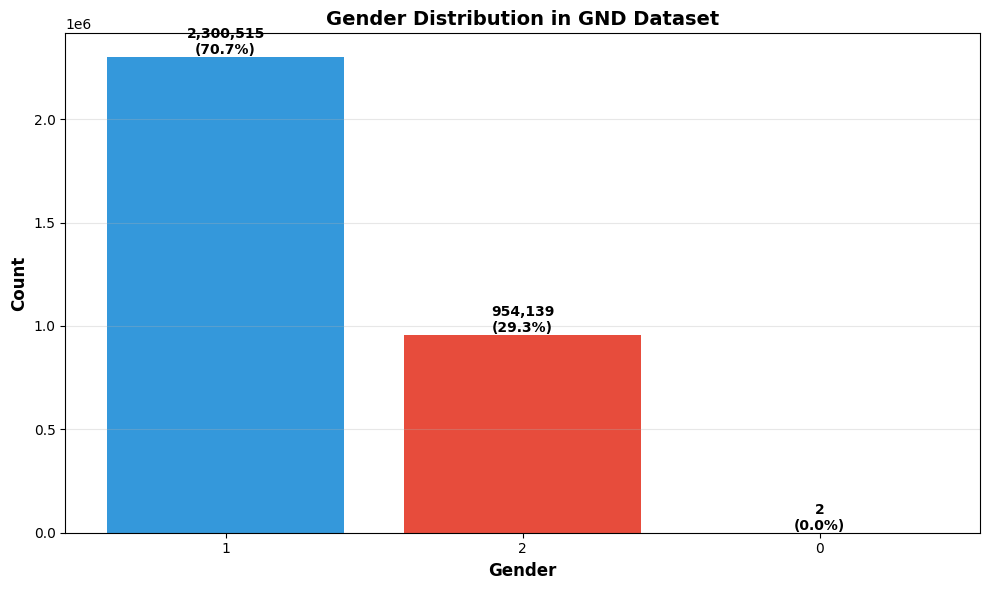

In [13]:
# Gender distribution
print("Gender Distribution:")
print("="*60)
gender_counts = df_gnd.group_by('gender').agg(pl.count().alias('count')).sort('count', descending=True)
print(gender_counts)

# Visualize gender distribution
import matplotlib.pyplot as plt

gender_data = gender_counts.to_dict(as_series=False)
genders = gender_data['gender']
counts = gender_data['count']

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(genders, counts, color=['#3498db', '#e74c3c', '#95a5a6'])
ax.set_xlabel('Gender', fontsize=12, fontweight='bold')
ax.set_ylabel('Count', fontsize=12, fontweight='bold')
ax.set_title('Gender Distribution in GND Dataset', fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Add count labels on bars
for bar, count in zip(bars, counts):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{count:,}\n({count/len(df_gnd)*100:.1f}%)',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [14]:
# Sample records by gender
print("Sample records by gender:\n")

for gender in df_gnd['gender'].unique().to_list():
    print(f"\n{'='*60}")
    print(f"Sample {gender.upper()} entries:")
    print('='*60)
    sample = df_gnd.filter(pl.col('gender') == gender).head(5)
    for row in sample.iter_rows(named=True):
        print(f"  Name: {row['name']}")
        print(f"  Forename: {row['forename']}, Surname: {row['surname']}")
        print(f"  Birth: {row['birth_date']}, Death: {row['death_date']}")
        print(f"  Alt names: {row['alt_names_count']}")
        print()

Sample records by gender:


Sample 2 entries:
  Name: Anna Sophie
  Forename: None, Surname: None
  Birth: 1638, Death: 1683
  Alt names: 5

  Name: Mornay, Charlotte Arbaleste de
  Forename: Charlotte Arbaleste de, Surname: Mornay
  Birth: 1548, Death: 1606
  Alt names: 19

  Name: Aubigny von Engelbrunner, Nina d'
  Forename: Nina d', Surname: Aubigny von Engelbrunner
  Birth: 1770, Death: 1847
  Alt names: 12

  Name: Bourette, Charlotte
  Forename: Charlotte, Surname: Bourette
  Birth: 1714, Death: 1784
  Alt names: 2

  Name: Choiseul-Gouffier, Sophie de Tisenhaus de
  Forename: Sophie de Tisenhaus de, Surname: Choiseul-Gouffier
  Birth: 1790, Death: 1878
  Alt names: 12


Sample 1 entries:
  Name: Bauer, Johann Gottfried
  Forename: Johann Gottfried, Surname: Bauer
  Birth: 1695, Death: 1763
  Alt names: 18

  Name: Baur, Johann Wilhelm
  Forename: Johann Wilhelm, Surname: Baur
  Birth: 1607, Death: 1642
  Alt names: 11

  Name: Mosca, Giuseppe
  Forename: Giuseppe, S

## 6. Prepare Dataset for Classification

Prepare the data for training machine learning classifiers.

In [15]:
# Check if df_gnd exists and has data
if 'df_gnd' not in dir() or df_gnd is None:
    print("⚠️  ERROR: df_gnd does not exist or is empty!")
    print("   Please run the previous cells to load the GND dataset first.")
else:
    # Translate GND gender codes: 1=male, 2=female, 0=unknown
    print("Translating GND gender codes...")
    print(f"Original gender values: {df_gnd['gender'].unique().sort().to_list()}")

    df_gnd = df_gnd.with_columns(
        pl.col('gender').replace({
            1: 'male',
            2: 'female',
            0: 'unknown'
        }).alias('gender')
    )

    print(f"Translated gender values: {df_gnd['gender'].unique().sort().to_list()}")

    # Filter to only male/female (drop unknown)
    df_train = df_gnd.filter(pl.col('gender').is_in(['male', 'female']))

    print(f"\nTraining dataset size: {len(df_train):,} records")

    if len(df_train) > 0:
        print(f"\nGender distribution in training set:")
        print(df_train.group_by('gender').agg(pl.len().alias('count')).sort('gender'))

        # Check data quality
        print(f"\nData Quality:")
        print(f"Records with forename: {df_train['forename'].is_not_null().sum():,} ({df_train['forename'].is_not_null().sum()/len(df_train)*100:.2f}%)")
        print(f"Records with surname: {df_train['surname'].is_not_null().sum():,} ({df_train['surname'].is_not_null().sum()/len(df_train)*100:.2f}%)")
        print(f"Records with birth_date: {df_train['birth_date'].is_not_null().sum():,} ({df_train['birth_date'].is_not_null().sum()/len(df_train)*100:.2f}%)")
        print(f"Records with death_date: {df_train['death_date'].is_not_null().sum():,} ({df_train['death_date'].is_not_null().sum()/len(df_train)*100:.2f}%)")
    else:
        print("⚠️  WARNING: df_train is empty after filtering!")
        print("   No 'male' or 'female' records found after translation.")

Translating GND gender codes...
Original gender values: ['0', '1', '2']
Translated gender values: ['female', 'male', 'unknown']

Training dataset size: 3,254,654 records

Gender distribution in training set:
shape: (2, 2)
┌────────┬─────────┐
│ gender ┆ count   │
│ ---    ┆ ---     │
│ str    ┆ u32     │
╞════════╪═════════╡
│ female ┆ 954139  │
│ male   ┆ 2300515 │
└────────┴─────────┘

Data Quality:
Records with forename: 3,181,580 (97.75%)
Records with surname: 3,181,580 (97.75%)
Records with birth_date: 1,949,607 (59.90%)
Records with death_date: 819,983 (25.19%)


In [16]:
# Save the processed dataset
output_file = data_dir / 'gnd_persons_with_gender.parquet'
df_train.write_parquet(output_file)

print(f"✓ Dataset saved to: {output_file}")
print(f"  File size: {output_file.stat().st_size / (1024*1024):.2f} MB")
print(f"  Records: {len(df_train):,}")
print(f"\nDataset ready for classifier training!")

✓ Dataset saved to: /mnt/data/userfiles/westphal/schleiermacher/gender/gender/data/raw/GND/gnd_persons_with_gender.parquet
  File size: 94.79 MB
  Records: 3,254,654

Dataset ready for classifier training!
